Mean of samples: 0.34256273059691333
Theoretical mean (1/rate): 0.3333333333333333


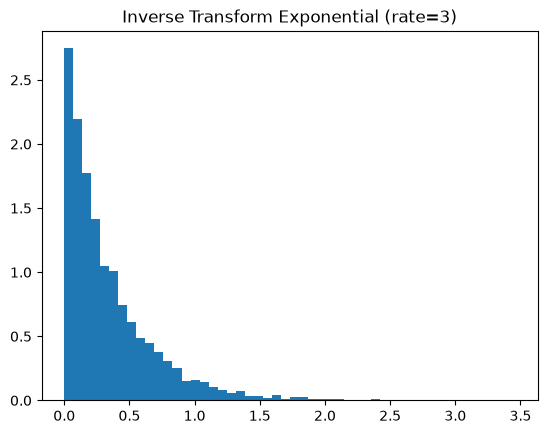

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Inverse CDF for Exp(rate) is -ln(1-u)/rate
u = np.random.uniform(0, 1, 5000)
rate = 3
exp_samples = -np.log(1 - u) / rate

print("Mean of samples:", np.mean(exp_samples))
print("Theoretical mean (1/rate):", 1/rate)

plt.hist(exp_samples, bins=50, density=True)
plt.title("Inverse Transform Exponential (rate=3)")
plt.show()

In [2]:
probs = [0.1, 0.6, 0.3]
categories = ['A', 'B', 'C']

samples = np.random.choice(categories, size=10000, p=probs)

import collections
print("Counts:", collections.Counter(samples))

Counts: Counter({np.str_('B'): 6019, np.str_('C'): 2943, np.str_('A'): 1038})


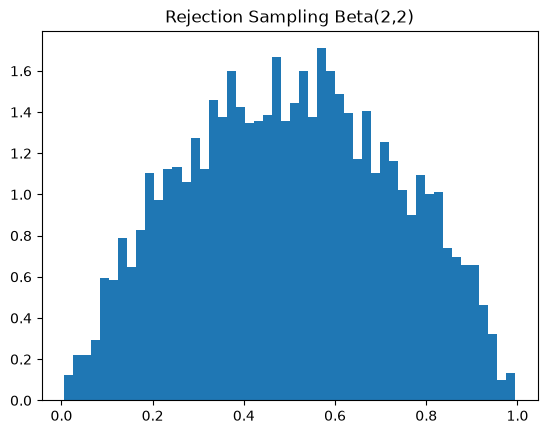

In [3]:
# Beta(2,2) pdf is proportional to x(1-x). Max value is 1.5.
samples = []
while len(samples) < 5000:
    x = np.random.uniform(0, 1)
    y = np.random.uniform(0, 1.5) # Envelope M=1.5
    
    # Accept if y < f(x)
    if y < 6 * x * (1 - x):
        samples.append(x)

plt.hist(samples, bins=50, density=True)
plt.title("Rejection Sampling Beta(2,2)")
plt.show()

**Q4: Particle Filter Steps**
1. **Initialize:** Generate an initial set of particles (samples) representing the prior distribution.
2. **Predict:** Propagate the particles forward through the state transition model (add process noise).
3. **Update (Weight):** Calculate the likelihood of the observed data given each particle, and assign weights based on how well they match the observation.
4. **Resample:** Multiply particles with high weights and drop those with low weights to focus on the most probable states.

**Q5: Non-uniform SBC rank histogram**
In Simulation-Based Calibration (SBC), uniform histograms indicate a well-calibrated model. A non-uniform histogram indicates:
* **U-shape:** The posterior is too narrow (overconfident). The true parameter falls in the tails too often.
* **Bell-shape (inverted U):** The posterior is too wide (underconfident). The true parameter falls in the middle too often.
* **Skewed:** The model is biased.